In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install onnx

import os, json, time, random, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import sigmoid_focal_loss
from torch.utils.flop_counter import FlopCounterMode

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
LOCAL_PROCESSED = "/content/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{BASE_DIR}/predictions"
RESULTS_CSV = f"{RESULTS_DIR}/results.csv"
for d in [LOCAL_PROCESSED, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, PREDICTIONS_DIR]:
  os.makedirs(d, exist_ok=True)

W, H = 640, 224
DS = {'culane': dict(w=1640, h=590, crop=236), 'bdd': dict(w=1280, h=720, crop=302)}
LINE_WIDTH = {'culane': 30, 'bdd': round(30 * 1280 / 1640)}
SPLIT_DS = {'train': 'culane', 'val': 'culane', 'test_culane': 'culane', 'test_bdd': 'bdd'}

In [3]:
def load(name):
  src = f"{PROCESSED_DIR}/{name}"
  dst = f"{LOCAL_PROCESSED}/{name}"
  if not os.path.exists(f"{dst}/meta.csv"):
    shutil.copytree(src, dst, dirs_exist_ok=True)
  images = np.load(f"{dst}/images.npy", mmap_mode='r')
  lanes = np.load(f"{dst}/lanes.npy")
  meta = pd.read_csv(f"{dst}/meta.csv")
  return images, lanes, meta

def resample(x, y):
  order = np.argsort(y)
  x, y = x[order], y[order]
  rows = np.arange(H)
  out = np.full(H, np.nan, np.float32)
  inside = (rows >= y[0]) & (rows <= y[-1])
  out[inside] = np.interp(rows[inside], y, x)
  return out

def to_orig(lanes, ds):
  c = DS[ds]
  x = lanes * c['w'] / W
  y = np.arange(H) * (c['h'] - c['crop']) / H + c['crop']
  return x, y

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
  img = np.array(img)
  for x, color in zip(lanes, colors):
    rows = np.where(np.isfinite(x))[0]
    if len(rows) > 1:
      points = np.stack([x[rows], rows], 1).round().astype(np.int32)
      cv2.polylines(img, [points], False, color, thickness)
  return img

def show_pred(images, gt, pred, idx, title, path=None):
  n_rows = (len(idx) + 2) // 3
  plt.figure(figsize=(18, 2.6 * n_rows))
  for j, i in enumerate(idx):
    img = draw(images[i], gt[i], thickness=6)
    img = draw(img, pred[j], colors=((255, 255, 0), (0, 255, 255)))
    plt.subplot(n_rows, 3, j + 1)
    plt.imshow(img)
    plt.axis('off')
  plt.suptitle(title)
  plt.tight_layout()
  if path:
    plt.savefig(path, dpi=120, bbox_inches='tight')
  plt.show()

def hardware():
  cpu = 'cpu'
  for line in open('/proc/cpuinfo'):
    if 'model name' in line:
      cpu = line.split(':')[1].strip()
      break
  gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
  return cpu, gpu

def log_result(**row):
  table = pd.DataFrame([{'time': time.strftime('%Y-%m-%d %H:%M'), **row}])
  if os.path.exists(RESULTS_CSV):
    table = pd.concat([pd.read_csv(RESULTS_CSV), table], ignore_index=True)
  table.to_csv(RESULTS_CSV, index=False)

def save_predictions(run, split, lanes, conf, sigma):
  os.makedirs(f"{PREDICTIONS_DIR}/{run}", exist_ok=True)
  np.savez_compressed(f"{PREDICTIONS_DIR}/{run}/{split}.npz", lanes=lanes, conf=conf, sigma=sigma)

In [4]:
def lane_mask(x, ds):
  c = DS[ds]
  xo, yo = to_orig(x, ds)
  mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
  rows = np.where(np.isfinite(xo))[0]
  if len(rows) > 1:
    points = np.stack([xo[rows], yo[rows] - c['crop']], 1).round().astype(np.int32)
    cv2.polylines(mask, [points], False, 1, LINE_WIDTH[ds])
  return mask

def iou(a, b):
  union = np.count_nonzero(a | b)
  if union == 0:
    return 0.0
  return np.count_nonzero(a & b) / union

def frame_ious(pred, gt, ds):
  pred_masks, gt_masks = [], []
  for k in range(2):
    pred_masks.append(lane_mask(pred[k], ds) if np.isfinite(pred[k]).sum() > 1 else None)
    gt_masks.append(lane_mask(gt[k], ds) if np.isfinite(gt[k]).sum() > 1 else None)
  side = []
  for k in range(2):
    if pred_masks[k] is not None and gt_masks[k] is not None:
      side.append(iou(pred_masks[k], gt_masks[k]))
    else:
      side.append(np.nan)
  P = [m for m in pred_masks if m is not None]
  G = [m for m in gt_masks if m is not None]
  matched = []
  if P and G:
    M = np.array([[iou(p, g) for g in G] for p in P])
    r, c = linear_sum_assignment(-M)
    matched = list(M[r, c])
  return {'n_pred': len(P), 'n_gt': len(G), 'matched': matched, 'side': side,
          'pred_on': [m is not None for m in pred_masks], 'gt_on': [m is not None for m in gt_masks]}

def prf(tp, fp, fn):
  if tp + fp + fn == 0:
    return np.nan, np.nan, np.nan
  p = tp / (tp + fp) if tp + fp > 0 else 0.0
  r = tp / (tp + fn) if tp + fn > 0 else 0.0
  f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
  return p, r, f1

def score(records, thr):
  tp = sum(sum(m > thr for m in r['matched']) for r in records)
  n_pred = sum(r['n_pred'] for r in records)
  n_gt = sum(r['n_gt'] for r in records)
  p, r, f1 = prf(tp, n_pred - tp, n_gt - tp)
  out = {'precision': p, 'recall': r, 'f1': f1, 'fp': n_pred - tp}
  for k, name in enumerate(['left', 'right']):
    tp_side = sum(1 for r in records if r['side'][k] > thr)
    n_pred_side = sum(r['pred_on'][k] for r in records)
    n_gt_side = sum(r['gt_on'][k] for r in records)
    out[f'f1_{name}'] = prf(tp_side, n_pred_side - tp_side, n_gt_side - tp_side)[2]
  return out

def evaluate(pred_lanes, split, idx=None):
  _, gt_lanes, meta = load(split)
  ds = SPLIT_DS[split]
  if idx is None:
    idx = np.arange(len(meta))

  def one_frame(j):
    return frame_ious(pred_lanes[j], gt_lanes[idx[j]], ds)

  with ThreadPoolExecutor(8) as pool:
    records = list(pool.map(one_frame, range(len(idx))))
  conditions = meta.condition.values[idx]
  rows = []
  for c in ['all'] + sorted(set(conditions)):
    rec = [r for r, k in zip(records, conditions) if c == 'all' or k == c]
    row = {'condition': c, 'n': len(rec)}
    row.update(score(rec, 0.5))
    row['f1@0.7'] = score(rec, 0.7)['f1']
    rows.append(row)
  return pd.DataFrame(rows).set_index('condition'), records

In [5]:
N_ROWS, N_CELLS = 36, 120
ROWS = np.linspace(10, H - 1, N_ROWS).astype(int)
X_MIN, X_MAX = -0.25 * W, 1.25 * W
CELL = (X_MAX - X_MIN) / N_CELLS
MIN_ROWS = 4
EPOCHS, BATCH, LR = 30, 32, 4e-4
LOSS_WEIGHTS = {'position': 1.0, 'l1': 0.2, 'exist': 5.0, 'aux': 0.5}
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def augment(img, lanes):
  if random.random() < 0.5:
    img = img[:, ::-1].copy()
    lanes = (W - 1 - lanes)[::-1].copy()
  if random.random() < 0.7:
    M = cv2.getRotationMatrix2D((W / 2, H), random.uniform(-4, 4), random.uniform(0.9, 1.1))
    M[0, 2] += random.uniform(-0.05, 0.05) * W
    M[1, 2] += random.uniform(-0.05, 0.05) * H
    img = cv2.warpAffine(img, M, (W, H))
    for k in range(2):
      rows = np.where(np.isfinite(lanes[k]))[0]
      if len(rows) > 1:
        x_new = M[0, 0] * lanes[k][rows] + M[0, 1] * rows + M[0, 2]
        y_new = M[1, 0] * lanes[k][rows] + M[1, 1] * rows + M[1, 2]
        lanes[k] = resample(x_new, y_new)
  img = img.astype(np.float32) * random.uniform(0.7, 1.3) + random.uniform(-30, 30)
  img = np.clip(img, 0, 255)
  if random.random() < 0.2:
    img = 255 * (img / 255) ** random.uniform(1.8, 2.8)
  elif random.random() < 0.3:
    img = 255 * (img / 255) ** random.uniform(0.7, 1.4)
  if random.random() < 0.2:
    img = cv2.GaussianBlur(img, (5, 5), 0)
  if random.random() < 0.2:
    img = img + np.random.normal(0, 8, img.shape)
  return np.clip(img, 0, 255).astype(np.uint8), lanes

class LaneDataset(Dataset):
  def __init__(self, split, train=False, size=(W, H), idx=None):
    self.images, self.lanes, meta = load(split)
    self.idx = np.arange(len(meta)) if idx is None else idx
    self.train = train
    self.size = size

  def __len__(self):
    return len(self.idx)

  def __getitem__(self, j):
    i = self.idx[j]
    img = np.array(self.images[i])
    lanes = self.lanes[i].copy()
    if self.train:
      img, lanes = augment(img, lanes)
    w, h = self.size
    img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
    img = (img / 255.0 - MEAN) / STD

    x = lanes[:, ROWS]
    present = np.isfinite(x) & (x >= X_MIN) & (x < X_MAX)
    target = (np.nan_to_num(x) - X_MIN) / CELL - 0.5
    target = np.clip(target, 0, N_CELLS - 1)

    mask = np.zeros((h // 8, w // 8), np.uint8)
    for k in range(2):
      rows = np.where(np.isfinite(lanes[k]))[0]
      if len(rows) > 1:
        points = np.stack([lanes[k][rows] * w / 8 / W, rows * h / 8 / H], 1).round().astype(np.int32)
        cv2.polylines(mask, [points], False, k + 1, 2)

    img = torch.tensor(img.transpose(2, 0, 1), dtype=torch.float32)
    return img, torch.tensor(target, dtype=torch.float32), torch.tensor(present), torch.tensor(mask, dtype=torch.long)

In [6]:
class RowAnchorNet(nn.Module):
  def __init__(self, width=W, channels=96):
    super().__init__()
    resnet = torchvision.models.resnet18(weights='IMAGENET1K_V1')
    self.stage2 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1, resnet.layer2)
    self.stage3 = resnet.layer3
    self.stage4 = resnet.layer4
    self.reduce3 = nn.Conv2d(256, channels, 1)
    self.reduce4 = nn.Conv2d(512, channels, 1)
    self.row_embedding = nn.Parameter(torch.zeros(1, channels, N_ROWS, 1))
    features_per_row = channels * (width // 16)
    self.position_head = nn.Linear(features_per_row, 2 * N_CELLS)
    self.exist_head = nn.Linear(features_per_row, 2)
    self.aux_head = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 3, 1))

  def forward(self, x):
    f2 = self.stage2(x)
    f3 = self.stage3(f2)
    f4 = self.stage4(f3)
    f = self.reduce3(f3) + F.interpolate(self.reduce4(f4), size=f3.shape[2:], mode='bilinear')
    f = F.interpolate(f, size=(N_ROWS, f.shape[3]), mode='bilinear')
    f = F.relu(f + self.row_embedding)
    f = f.permute(0, 2, 1, 3).flatten(2)
    position = self.position_head(f).reshape(-1, N_ROWS, 2, N_CELLS).transpose(1, 2)
    exist = self.exist_head(f).transpose(1, 2)
    if self.training:
      return position, exist, self.aux_head(f2)
    return position, exist

model = RowAnchorNet()
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M parameters')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 224MB/s]

12.257397 M parameters


In [7]:
def dice_loss(logits, mask):
  prob = logits.softmax(1)[:, 1:]
  target = F.one_hot(mask, 3).permute(0, 3, 1, 2)[:, 1:].float()
  overlap = (prob * target).sum()
  total = prob.sum() + target.sum()
  return 1 - (2 * overlap + 1) / (total + 1)

def compute_loss(position, exist, aux, target, present, mask):
  present = present.float()
  n = present.sum().clamp(min=1)

  left = target.floor().long().clamp(0, N_CELLS - 2)
  w_right = target - left
  soft_target = (1 - w_right)[..., None] * F.one_hot(left, N_CELLS) + w_right[..., None] * F.one_hot(left + 1, N_CELLS)
  log_prob = F.log_softmax(position, dim=-1)
  position_loss = (-(soft_target * log_prob).sum(-1) * present).sum() / n

  cells = torch.arange(N_CELLS, device=position.device)
  expected = (position.softmax(-1) * cells).sum(-1)
  l1_loss = ((expected - target).abs() * present).sum() / n

  exist_loss = sigmoid_focal_loss(exist, present, alpha=-1, gamma=2, reduction='mean')
  aux_loss = F.cross_entropy(aux, mask) + dice_loss(aux, mask)

  w = LOSS_WEIGHTS
  return w['position'] * position_loss + w['l1'] * l1_loss + w['exist'] * exist_loss + w['aux'] * aux_loss

In [8]:
@torch.no_grad()
def predict_raw(model, split, idx=None, size=(W, H)):
  model.eval()
  loader = DataLoader(LaneDataset(split, False, size, idx), batch_size=64, num_workers=8)
  cells = torch.arange(N_CELLS).cuda()
  means, spreads, probs = [], [], []
  for img, _, _, _ in loader:
    with torch.autocast('cuda', dtype=torch.bfloat16):
      position, exist = model(img.cuda())
    p = position.float().softmax(-1)
    mean = (p * cells).sum(-1)
    spread = ((p * (cells - mean[..., None]) ** 2).sum(-1)).sqrt()
    means.append(mean.cpu().numpy())
    spreads.append(spread.cpu().numpy())
    probs.append(exist.float().sigmoid().cpu().numpy())
  return np.concatenate(means), np.concatenate(spreads), np.concatenate(probs)

def to_lanes(raw, threshold=0.5):
  mean, spread, prob = raw
  xs = X_MIN + (mean + 0.5) * CELL
  sig = spread * CELL
  n = len(mean)
  lanes = np.full((n, 2, H), np.nan, np.float32)
  sigma = np.full((n, 2, H), np.nan, np.float32)
  conf = np.zeros((n, 2), np.float32)
  for i in range(n):
    for k in range(2):
      on = prob[i, k] > threshold
      if on.sum() >= MIN_ROWS:
        lanes[i, k] = resample(xs[i, k, on], ROWS[on])
        sigma[i, k] = resample(sig[i, k, on], ROWS[on])
        conf[i, k] = prob[i, k, on].mean()
  return lanes, conf, sigma

def train(run, size=(W, H), epochs=EPOCHS, train_idx=None, val_idx=None):
  torch.manual_seed(SEED)
  model = RowAnchorNet(size[0]).cuda()
  loader = DataLoader(LaneDataset('train', True, size, train_idx), batch_size=BATCH, shuffle=True, num_workers=8, drop_last=True)
  optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=epochs * len(loader), pct_start=0.1)
  os.makedirs(f"{MODELS_DIR}/{run}", exist_ok=True)
  history = []
  best_f1 = -1
  for epoch in range(epochs):
    model.train()
    total_loss = 0
    for img, target, present, mask in tqdm(loader, leave=False):
      img, target, present, mask = img.cuda(), target.cuda(), present.cuda(), mask.cuda()
      with torch.autocast('cuda', dtype=torch.bfloat16):
        position, exist, aux = model(img)
      loss = compute_loss(position.float(), exist.float(), aux.float(), target, present, mask)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      scheduler.step()
      total_loss += loss.item()

    f1 = np.nan
    if val_idx is not None:
      lanes, _, _ = to_lanes(predict_raw(model, 'val', val_idx, size))
      f1 = evaluate(lanes, 'val', val_idx)[0].loc['all', 'f1']
      if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), f"{MODELS_DIR}/{run}/best.pt")
    history.append({'epoch': epoch + 1, 'loss': round(total_loss / len(loader), 4), 'val_f1': round(f1, 4)})
    print(history[-1])

  if val_idx is not None:
    model.load_state_dict(torch.load(f"{MODELS_DIR}/{run}/best.pt"))
    pd.DataFrame(history).to_csv(f"{MODELS_DIR}/{run}/history.csv", index=False)
  return model, pd.DataFrame(history)

  0%|          | 0/4 [00:00<?, ?it/s]

{'epoch': 1, 'loss': 8.7872, 'val_f1': nan}


  0%|          | 0/4 [00:00<?, ?it/s]

{'epoch': 2, 'loss': 7.7461, 'val_f1': nan}


  0%|          | 0/4 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f79e8eacb80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7f79e8eacb80>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

... (75 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

{'epoch': 39, 'loss': 2.4367, 'val_f1': nan}


  0%|          | 0/4 [00:00<?, ?it/s]

{'epoch': 40, 'loss': 2.466, 'val_f1': nan}


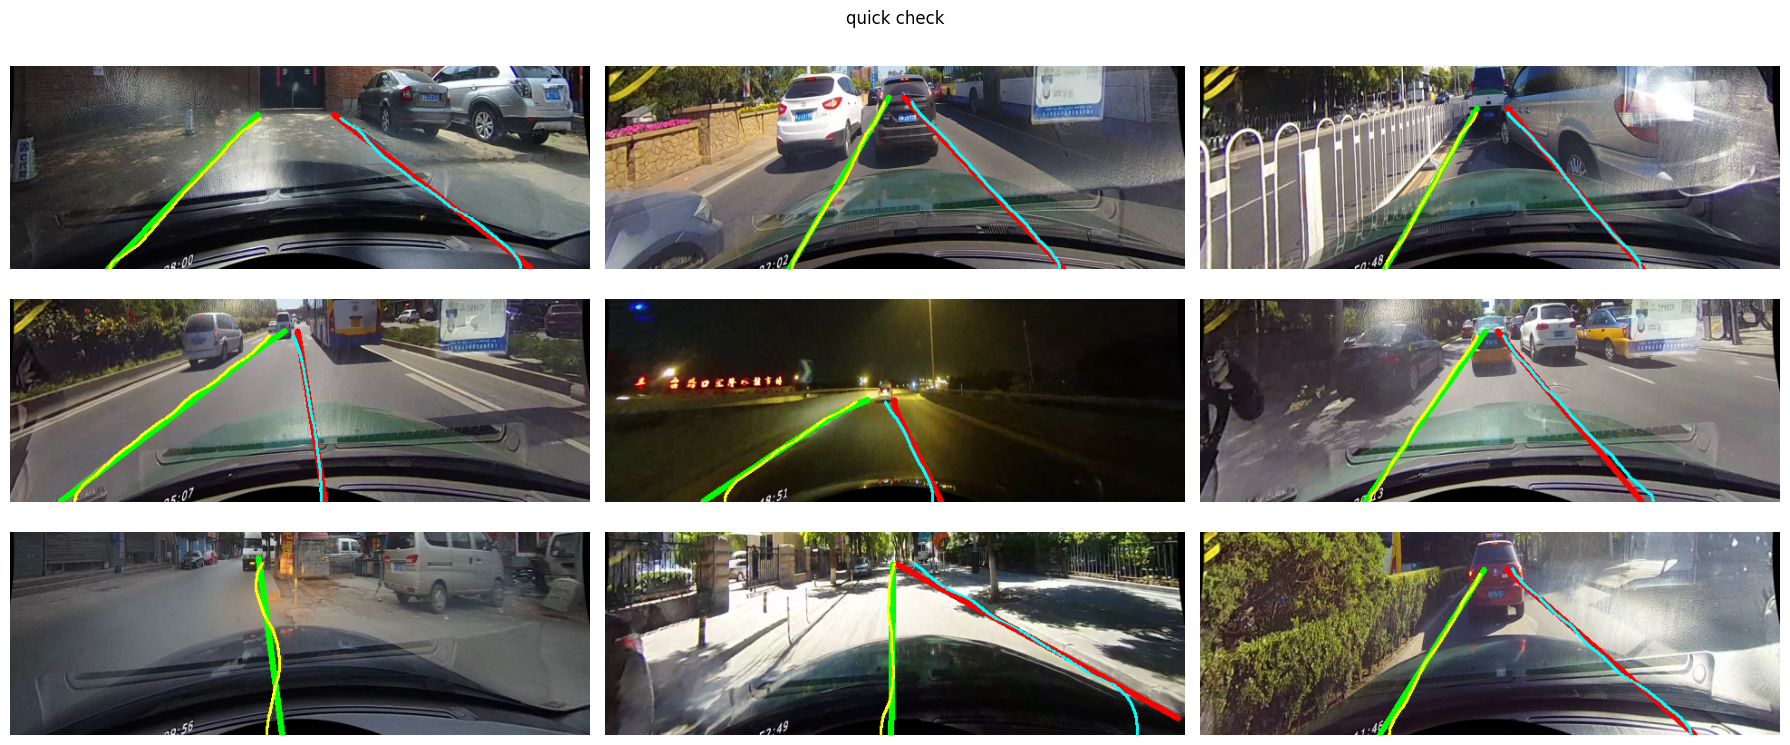

In [ ]:
model, history = train('quick_check', epochs=40, train_idx=np.arange(128))
images_train, lanes_train, _ = load('train')
pred, _, _ = to_lanes(predict_raw(model, 'train', np.arange(9)))
show_pred(images_train, lanes_train, pred, np.arange(9), 'quick check')

In [ ]:
RUN = 'rowanchor_r18_640x224'
val_idx = np.sort(np.random.default_rng(SEED).choice(9500, 2000, replace=False))
model, history = train(RUN, val_idx=val_idx)
history.plot(x='epoch', y=['loss', 'val_f1'], subplots=True, figsize=(10, 5))
plt.savefig(f"{FIGURES_DIR}/{RUN}_curves.png")
plt.show()

  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 1, 'loss': 3.826, 'val_f1': np.float64(0.5323)}


  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 2, 'loss': 2.483, 'val_f1': np.float64(0.6529)}


  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 3, 'loss': 2.2459, 'val_f1': np.float64(0.6892)}


... (43 outputs left out)

{'epoch': 25, 'loss': 1.2871, 'val_f1': np.float64(0.766)}


  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 26, 'loss': 1.2726, 'val_f1': np.float64(0.7631)}


  0%|          | 0/1406 [00:00<?, ?it/s]

In [9]:
RUN = 'rowanchor_r18_640x224'
val_idx = np.sort(np.random.default_rng(SEED).choice(9500, 2000, replace=False))
model = RowAnchorNet().cuda()
model.load_state_dict(torch.load(f"{MODELS_DIR}/{RUN}/best.pt"))
print('loaded', RUN)

loaded rowanchor_r18_640x224


In [10]:
def finish(run, model, size=(W, H)):
  raw = predict_raw(model, 'val', None, size)
  best_threshold, best_f1, table = None, -1, None
  for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    lanes, _, _ = to_lanes(raw, threshold)
    t = evaluate(lanes, 'val')[0]
    print(f"threshold {threshold}: val F1 {t.loc['all', 'f1']:.4f}")
    if t.loc['all', 'f1'] > best_f1:
      best_threshold, best_f1, table = threshold, t.loc['all', 'f1'], t

  x = torch.zeros(1, 3, size[1], size[0]).cuda()
  model.eval()
  with torch.no_grad():
    for _ in range(20):
      model(x)
    torch.cuda.synchronize()
    start = time.time()
    for _ in range(100):
      model(x)
    torch.cuda.synchronize()
    ms = (time.time() - start) * 10
    with FlopCounterMode(display=False) as counter:
      model(x)
  gflops = counter.get_total_flops() / 1e9
  params = sum(p.numel() for p in model.parameters())

  torch.onnx.export(model, x, f"{MODELS_DIR}/{run}/model.onnx", input_names=['image'],
                    output_names=['position', 'exist'], dynamo=False)
  config = {'backbone': 'resnet18', 'input': list(size), 'rows': ROWS.tolist(), 'n_cells': N_CELLS,
            'x_range': [X_MIN, X_MAX], 'min_rows': MIN_ROWS, 'threshold': best_threshold,
            'epochs': EPOCHS, 'batch': BATCH, 'lr': LR, 'loss_weights': LOSS_WEIGHTS, 'seed': SEED}
  yaml.safe_dump(config, open(f"{MODELS_DIR}/{run}/config.yaml", 'w'))
  metrics = table.loc['all'].to_dict()
  metrics.update({'threshold': best_threshold, 'ms_gpu': ms, 'params': params, 'gflops': gflops})
  json.dump(metrics, open(f"{MODELS_DIR}/{run}/metrics.json", 'w'), indent=2, default=float)
  cpu, gpu = hardware()
  log_result(run=run, detector='row_anchor', backbone='resnet18', tracker='none', split='val',
             resolution=f"{size[0]}x{size[1]}", params=params, gflops=round(gflops, 2), ms_per_frame=round(ms, 2),
             device='gpu', hardware=gpu, threshold=best_threshold, **table.loc['all'].round(4).to_dict())

  for split in ['test_culane', 'test_bdd']:
    lanes, conf, sigma = to_lanes(predict_raw(model, split, None, size), best_threshold)
    save_predictions(run, split, lanes, conf, sigma)
  display(table.round(4))
  print(f"{run}: threshold {best_threshold} | {ms:.2f} ms | {params / 1e6:.2f} M parameters | {gflops:.2f} GFLOPs")
  return best_threshold

threshold = finish(RUN, model)

threshold 0.3: val F1 0.7509
threshold 0.4: val F1 0.7526
threshold 0.5: val F1 0.7524
threshold 0.6: val F1 0.7503
threshold 0.7: val F1 0.7466


,n,precision,recall,f1,fp,f1_left,f1_right,f1@0.7
condition,,,,,,,,
all,9500,0.7541,0.7512,0.7526,4298,0.7713,0.7337,0.5887
unknown,9500,0.7541,0.7512,0.7526,4298,0.7713,0.7337,0.5887


rowanchor_r18_640x224: threshold 0.4 | 3.41 ms | 12.26 M parameters | 10.47 GFLOPs


In [11]:
images_val, lanes_val, _ = load('val')
pred_val, _, _ = to_lanes(predict_raw(model, 'val'), threshold)
_, records = evaluate(pred_val, 'val')
idx = np.random.default_rng(SEED).choice(len(pred_val), 9, replace=False)
show_pred(images_val, lanes_val, pred_val[idx], idx, 'random val frames', f"{FIGURES_DIR}/{RUN}_random.png")
frame_score = []
for r in records:
  if any(r['gt_on']):
    frame_score.append(np.nan_to_num(r['side']).mean())
  else:
    frame_score.append(9)
worst = np.argsort(frame_score)[:6]
show_pred(images_val, lanes_val, pred_val[worst], worst, 'worst val frames', f"{FIGURES_DIR}/{RUN}_worst.png")

Output hidden; open in https://colab.research.google.com to view.

In [12]:
table, records = evaluate(pred_val, 'val')
for thr in [0.1, 0.3, 0.5, 0.7]:
	s = score(records, thr)
	print('IoU >', thr, '| precision', round(s['precision'], 3), '| recall', round(s['recall'], 3), '| F1', round(s['f1'], 3))

IoU > 0.1 | precision 0.92 | recall 0.917 | F1 0.918
IoU > 0.3 | precision 0.842 | recall 0.839 | F1 0.841
IoU > 0.5 | precision 0.754 | recall 0.751 | F1 0.753
IoU > 0.7 | precision 0.59 | recall 0.588 | F1 0.589


In [13]:
for size in [(512, 192), (384, 128)]:
	run = f"rowanchor_r18_{size[0]}x{size[1]}"
	if os.path.exists(f"{MODELS_DIR}/{run}/metrics.json"):
		print(run, 'already done')
		continue
	m, _ = train(run, size, val_idx=val_idx)
	finish(run, m, size)

  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 1, 'loss': 3.9106, 'val_f1': np.float64(0.5336)}


  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 2, 'loss': 2.5293, 'val_f1': np.float64(0.5867)}


  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 3, 'loss': 2.2865, 'val_f1': np.float64(0.6592)}


... (116 outputs left out)

  0%|          | 0/1406 [00:00<?, ?it/s]

{'epoch': 30, 'loss': 1.2906, 'val_f1': np.float64(0.7354)}
threshold 0.3: val F1 0.7211
threshold 0.4: val F1 0.7211
threshold 0.5: val F1 0.7220
threshold 0.6: val F1 0.7212
threshold 0.7: val F1 0.7170


,n,precision,recall,f1,fp,f1_left,f1_right,f1@0.7
condition,,,,,,,,
all,9500,0.7287,0.7154,0.722,4673,0.7585,0.6852,0.5552
unknown,9500,0.7287,0.7154,0.722,4673,0.7585,0.6852,0.5552


rowanchor_r18_384x128: threshold 0.5 | 3.25 ms | 11.89 M parameters | 3.61 GFLOPs


In [ ]:
for size in [(512, 192), (384, 128)]:
  run = f"rowanchor_r18_{size[0]}x{size[1]}"
  m, _ = train(run, size, val_idx=val_idx)
  finish(run, m, size)

In [14]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()